# 01 — EDA & Feature Engineering for Bank Customer Churn

Goals:
- Load the bank churn dataset
- Clean & inspect fields
- Engineer banking-specific features
- Create train/val/test splits
- Save processed data for modeling


In [67]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split

# Display settings
pd.set_option("display.max_columns", 200)
sns.set(style="whitegrid")


In [70]:
# Load raw data

# Path to your CSV (adjust if needed)
DATA_PATH = "D:/Omar/Side Projects/Recommender System/data/bank_customer_churn_copy.csv"

df = pd.read_csv(DATA_PATH)

print(df.shape)

(100000, 24)


In [71]:
# Inspect schema

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 24 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   CustomerId                       100000 non-null  object 
 1   Surname                          100000 non-null  object 
 2   First Name                       100000 non-null  object 
 3   Date of Birth                    100000 non-null  object 
 4   Gender                           100000 non-null  object 
 5   Marital Status                   100000 non-null  object 
 6   Number of Dependents             100000 non-null  int64  
 7   Occupation                       100000 non-null  object 
 8   Income                           100000 non-null  float64
 9   Education Level                  100000 non-null  object 
 10  Address                          100000 non-null  object 
 11  Contact Information              100000 non-null  object 
 12  Cus

In [72]:
# Basic churn distribution & target cleaning

TARGET_COL = "Churn Flag"

# Ensure target is int (0/1)
df[TARGET_COL] = df[TARGET_COL].astype(int)

# Check class balance
churn_proportion = df[TARGET_COL].value_counts(normalize=True).rename("proportion")
print(churn_proportion)


Churn Flag
0    0.87807
1    0.12193
Name: proportion, dtype: float64


In [73]:
# Drop leakage + ID / personal columns

# Columns that should NEVER be used as features for modeling
# - Leakage: known only after churn
# - IDs/personal: not meaningful + high cardinality + privacy
cols_to_drop = [
    "CustomerId",
    "Surname",
    "First Name",
    "Address",
    "Contact Information",
    "Date of Birth",   # we'll drop raw DOB; could derive age later if needed
    "Churn Reason",
    "Churn Date",
]

df_model = df.drop(columns=cols_to_drop, errors="ignore")

print("Columns after dropping IDs/leakage:")
print(df_model.columns.tolist())


Columns after dropping IDs/leakage:
['Gender', 'Marital Status', 'Number of Dependents', 'Occupation', 'Income', 'Education Level', 'Customer Tenure', 'Customer Segment', 'Preferred Communication Channel', 'Credit Score', 'Credit History Length', 'Outstanding Loans', 'Churn Flag', 'Balance', 'NumOfProducts', 'NumComplaints']


In [75]:
# Quick numeric vs categorical breakdown

numeric_cols = df_model.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df_model.select_dtypes(include=["object"]).columns.tolist()

print("Numeric columns:", numeric_cols)
print()
print("Categorical columns:", categorical_cols)

Numeric columns: ['Number of Dependents', 'Income', 'Customer Tenure', 'Credit Score', 'Credit History Length', 'Outstanding Loans', 'Churn Flag', 'Balance', 'NumOfProducts', 'NumComplaints']

Categorical columns: ['Gender', 'Marital Status', 'Occupation', 'Education Level', 'Customer Segment', 'Preferred Communication Channel']


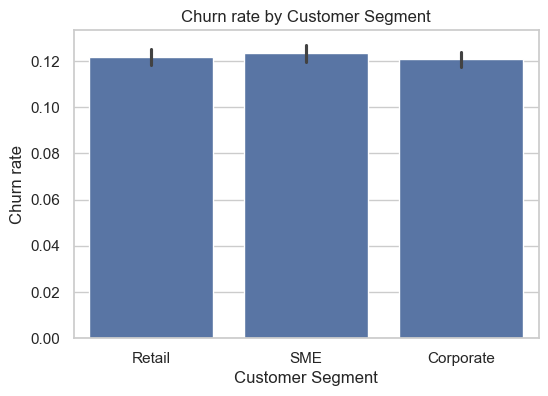

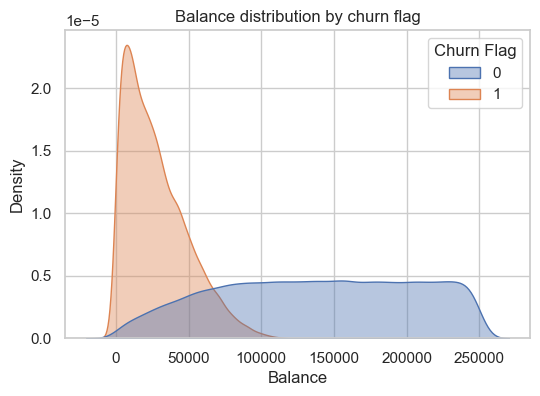

In [76]:
# Some quick EDA plots

# Example: churn rate by Customer Segment (if present)
if "Customer Segment" in df_model.columns:
    plt.figure(figsize=(6,4))
    sns.barplot(
        data=df_model,
        x="Customer Segment",
        y=TARGET_COL,
        estimator=np.mean
    )
    plt.title("Churn rate by Customer Segment")
    plt.ylabel("Churn rate")
    plt.show()

# Example: distribution of Balance by churn
if "Balance" in df_model.columns:
    plt.figure(figsize=(6,4))
    sns.kdeplot(
        data=df_model,
        x="Balance",
        hue=TARGET_COL,
        common_norm=False,
        fill=True,
        alpha=0.4
    )
    plt.title("Balance distribution by churn flag")
    plt.show()

In [77]:
# Define X, y and train/val/test splits

# Separate features and target
X = df_model.drop(columns=[TARGET_COL])
y = df_model[TARGET_COL]

# First split: train+val vs test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Second split: train vs val
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25,  # 0.25 * 0.8 = 0.2 of total
    stratify=y_train_full,
    random_state=42
)

X_train_raw.shape, X_val_raw.shape, X_test.shape


((60000, 15), (20000, 15), (20000, 15))

In [79]:
# Feature engineering (tenure buckets, balance flags, complaints)

def add_engineered_features(df_in, train_reference=None):
    """
    Add simple, banking-relevant engineered features.
    train_reference: DataFrame used to compute medians (for consistency),
                     typically the training set.
    """
    df = df_in.copy()

    # Tenure bucket (if column exists)
    if "Customer Tenure" in df.columns:
        df["tenure_bucket"] = pd.cut(
            df["Customer Tenure"],
            bins=[0, 6, 12, 36, 100],
            labels=["0-6m", "6-12m", "1-3y", "3y+"]
        )

    # High-balance flag (use training median for consistency)
    if "Balance" in df.columns and train_reference is not None and "Balance" in train_reference.columns:
        balance_median = train_reference["Balance"].median()
        df["high_balance"] = (df["Balance"] > balance_median).astype(int)

    # Complaints flag: any complaints vs none
    if "NumComplaints" in df.columns:
        df["has_complaints"] = (df["NumComplaints"] > 0).astype(int)

    return df

# Apply feature engineering:
X_train_fe = add_engineered_features(X_train_raw, train_reference=X_train_raw)
X_val_fe   = add_engineered_features(X_val_raw,   train_reference=X_train_raw)
X_test_fe  = add_engineered_features(X_test,      train_reference=X_train_raw)

X_train_fe.head()


,Gender,Marital Status,Number of Dependents,Occupation,Income,Education Level,Customer Tenure,Customer Segment,Preferred Communication Channel,Credit Score,Credit History Length,Outstanding Loans,Balance,NumOfProducts,NumComplaints,tenure_bucket,high_balance,has_complaints
59773,Male,Single,2,"Accountant, chartered",48492.89,Master's,23,Retail,Phone,630,27,28184.26,59708.88,1,10,1-3y,0,1
37072,Female,Divorced,5,Multimedia specialist,96410.65,Diploma,28,SME,Phone,346,2,47083.43,143042.64,3,5,1-3y,1,1
51584,Female,Single,3,"Investment banker, corporate",33887.43,Diploma,19,SME,Phone,586,28,22811.83,230964.87,3,1,1-3y,1,1
5596,Female,Divorced,2,Oceanographer,50480.53,Master's,13,Retail,Phone,701,25,37349.63,28666.31,5,1,1-3y,0,1
30830,Male,Married,4,Fisheries officer,80729.65,High School,7,Retail,Email,821,18,35051.31,43115.98,5,2,6-12m,0,1


In [80]:
# One-hot encoding (only small categoricals)

def encode(train, val, test):
    """
    One-hot encode a small, safe set of categorical columns and align
    columns across train/val/test.
    """
    # Only these categoricals get one-hot encoded
    desired_cat_cols = [
        "Gender",
        "Marital Status",
        "Education Level",
        "Customer Segment",
        "Preferred Communication Channel",
        "tenure_bucket",        # from feature engineering, if present
    ]

    # Keep only those that actually exist in the data
    cat_cols = [c for c in desired_cat_cols if c in train.columns]

    print("One-hot encoding these categorical columns:", cat_cols)

    train_enc = pd.get_dummies(train, columns=cat_cols, drop_first=True)
    val_enc   = pd.get_dummies(val,   columns=cat_cols, drop_first=True)
    test_enc  = pd.get_dummies(test,  columns=cat_cols, drop_first=True)

    # Make sure all three have the same columns (union of all)
    all_cols = train_enc.columns.union(val_enc.columns).union(test_enc.columns)

    train_enc = train_enc.reindex(columns=all_cols, fill_value=0)
    val_enc   = val_enc.reindex(columns=all_cols, fill_value=0)
    test_enc  = test_enc.reindex(columns=all_cols, fill_value=0)

    return train_enc, val_enc, test_enc

train_enc, val_enc, test_enc = encode(X_train_fe, X_val_fe, X_test_fe)

train_enc.shape, val_enc.shape, test_enc.shape


One-hot encoding these categorical columns: ['Gender', 'Marital Status', 'Education Level', 'Customer Segment', 'Preferred Communication Channel', 'tenure_bucket']


((60000, 24), (20000, 24), (20000, 24))

In [81]:
# Attach targets and final sanity checks

# Attach target column back to encoded sets
train_enc[TARGET_COL] = y_train.values
val_enc[TARGET_COL]   = y_val.values
test_enc[TARGET_COL]  = y_test.values

# Quick sanity: no object dtypes among features
feature_cols = [c for c in train_enc.columns if c != TARGET_COL]

print("Dtypes in encoded training features:")
print(train_enc[feature_cols].dtypes.value_counts())
print("Object columns:", train_enc[feature_cols].select_dtypes(include="object").columns.tolist())


Dtypes in encoded training features:
bool       12
int64       6
float64     3
int32       2
object      1
Name: count, dtype: int64
Object columns: ['Occupation']


In [82]:
# Save processed data for Notebook 2

OUTPUT_DIR = "processed_bank"
os.makedirs(OUTPUT_DIR, exist_ok=True)

train_enc.to_parquet(os.path.join(OUTPUT_DIR, "train.parquet"))
val_enc.to_parquet(os.path.join(OUTPUT_DIR, "val.parquet"))
test_enc.to_parquet(os.path.join(OUTPUT_DIR, "test.parquet"))

print("Saved processed train/val/test to:", OUTPUT_DIR)


Saved processed train/val/test to: processed_bank
